# Modelo de Clasificacion de Piezas de Ajedrez

Cuadernillo ajustado para entrenar con el dataset ubicado en `Dataset/Entrenamiento`.

Incluye:
- carga de dataset `train` y `Val`,
- entrenamiento con PyTorch,
- graficas de perdida y precision,
- matriz de confusion,
- pruebas con imagenes sueltas,
- prueba integrada con DroidCam + ArUco + segmentacion + clasificacion + matriz/tablero `python-chess`.


## 1. Instalacion opcional

Ejecuta esta celda solo si falta alguna libreria.

In [ ]:
# Ejecuta solo si hace falta:
# !pip install torch torchvision opencv-contrib-python matplotlib numpy pillow python-chess


## 2. Imports, rutas y configuracion

In [1]:
from pathlib import Path
import json
import random
import time
import urllib.request

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import clear_output, display, SVG

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

try:
    import chess
    import chess.svg
except ImportError:
    chess = None


def encontrar_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for path in [start, *start.parents]:
        if (path / "Dataset" / "Entrenamiento").exists():
            return path
    return Path.cwd()

ROOT = encontrar_root()
DATASET_DIR = ROOT / "Dataset" / "Entrenamiento"
TRAIN_DIR = DATASET_DIR / "train"
VAL_DIR = DATASET_DIR / "Val"
OUTPUT_DIR = ROOT / "Modelo de Clasificacion" / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = OUTPUT_DIR / "modelo_ajedrez_entrenamiento.pth"
CLASS_NAMES_PATH = OUTPUT_DIR / "class_names.json"
HISTORY_PATH = OUTPUT_DIR / "historial_entrenamiento.json"

IMG_SIZE = 100
BATCH_SIZE = 32
EPOCHS = 35
LEARNING_RATE = 8e-4
USE_AUGMENTATION = False  # Solo modifica imagenes en memoria durante entrenamiento; no cambia el dataset en disco.
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("ROOT:", ROOT)
print("Dataset:", DATASET_DIR)
print("Train:", TRAIN_DIR)
print("Val:", VAL_DIR)
print("Device:", device)


ROOT: c:\Users\User\Desktop\Brazo Robotico
Dataset: c:\Users\User\Desktop\Brazo Robotico\Dataset\Entrenamiento
Train: c:\Users\User\Desktop\Brazo Robotico\Dataset\Entrenamiento\train
Val: c:\Users\User\Desktop\Brazo Robotico\Dataset\Entrenamiento\Val
Device: cuda


## 3. Verificar dataset y clases

La carpeta `Val` esta con V mayuscula, por eso se usa exactamente esa ruta.

In [2]:
if not TRAIN_DIR.exists():
    raise FileNotFoundError(f"No existe TRAIN_DIR: {TRAIN_DIR}")
if not VAL_DIR.exists():
    raise FileNotFoundError(f"No existe VAL_DIR: {VAL_DIR}")

train_classes = sorted([p.name for p in TRAIN_DIR.iterdir() if p.is_dir()])
val_classes = sorted([p.name for p in VAL_DIR.iterdir() if p.is_dir()])

if train_classes != val_classes:
    print("Clases train:", train_classes)
    print("Clases val:", val_classes)
    raise ValueError("Las clases de train y Val no coinciden.")

class_names = train_classes
num_classes = len(class_names)

print(f"Numero de clases: {num_classes}")
print(class_names)

conteos = []
for cls in class_names:
    train_count = sum(1 for p in (TRAIN_DIR / cls).glob("**/*") if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"])
    val_count = sum(1 for p in (VAL_DIR / cls).glob("**/*") if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"])
    conteos.append((cls, train_count, val_count))
    print(f"{cls:16s} train={train_count:3d} val={val_count:3d}")

with open(CLASS_NAMES_PATH, "w", encoding="utf-8") as f:
    json.dump(class_names, f, ensure_ascii=False, indent=2)
print("Clases guardadas en:", CLASS_NAMES_PATH)

from collections import Counter

def resumen_tamanos_imagenes(base_dir):
    sizes = Counter()
    errores = []
    for p in Path(base_dir).rglob("*"):
        if p.is_file() and p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]:
            try:
                with Image.open(p) as im:
                    sizes[im.size] += 1
            except Exception as exc:
                errores.append((p, str(exc)))
    return sizes, errores

sizes_train, errores_train = resumen_tamanos_imagenes(TRAIN_DIR)
sizes_val, errores_val = resumen_tamanos_imagenes(VAL_DIR)
print("Tamanos train:", sizes_train.most_common())
print("Tamanos Val:", sizes_val.most_common())

esperado = (IMG_SIZE, IMG_SIZE)
if any(size != esperado for size in sizes_train) or any(size != esperado for size in sizes_val):
    print(f"ADVERTENCIA: hay imagenes que no son {esperado}. Se ajustaran en memoria con transforms.Resize, sin modificar archivos.")
else:
    print(f"Todas las imagenes revisadas ya estan en {esperado}; no se cambia el tamano del dataset en disco.")

if errores_train or errores_val:
    print("Errores leyendo imagenes:", errores_train[:5] + errores_val[:5])


Numero de clases: 13
['alfil_blanco', 'alfil_negro', 'caballo_blanco', 'caballo_negro', 'peon_blanco', 'peon_negro', 'reina_blanco', 'reina_negro', 'rey_blanco', 'rey_negro', 'torre_blanco', 'torre_negro', 'vacio']
alfil_blanco     train=256 val= 64
alfil_negro      train=256 val= 64
caballo_blanco   train=256 val= 64
caballo_negro    train=256 val= 64
peon_blanco      train=256 val= 64
peon_negro       train=256 val= 64
reina_blanco     train=234 val= 64
reina_negro      train=233 val= 64
rey_blanco       train=232 val= 64
rey_negro        train=231 val= 64
torre_blanco     train=256 val= 64
torre_negro      train=256 val= 64
vacio            train=256 val= 64
Clases guardadas en: c:\Users\User\Desktop\Brazo Robotico\Modelo de Clasificacion\outputs\class_names.json
Tamanos train: [((100, 100), 3234)]
Tamanos Val: [((100, 100), 832)]
Todas las imagenes revisadas ya estan en (100, 100); no se cambia el tamano del dataset en disco.


## 4. Transformaciones y DataLoaders

In [3]:
if USE_AUGMENTATION:
    train_transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.RandomApply([
            transforms.ColorJitter(brightness=0.18, contrast=0.18, saturation=0.10, hue=0.02)
        ], p=0.45),
        transforms.RandomAffine(degrees=4, translate=(0.02, 0.02), scale=(0.96, 1.04)),
        transforms.RandomPerspective(distortion_scale=0.06, p=0.15),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])
else:
    train_transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

train_data = datasets.ImageFolder(str(TRAIN_DIR), transform=train_transform)
val_data = datasets.ImageFolder(str(VAL_DIR), transform=val_transform)

# ImageFolder ordena clases alfabeticamente; verificamos que coincida con class_names.
class_names = train_data.classes
num_classes = len(class_names)
with open(CLASS_NAMES_PATH, "w", encoding="utf-8") as f:
    json.dump(class_names, f, ensure_ascii=False, indent=2)

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print("Train images:", len(train_data))
print("Val images:", len(val_data))
print("Classes:", class_names)
print("IMG_SIZE:", IMG_SIZE)
print("Augmentacion en memoria:", USE_AUGMENTATION)


Train images: 3234
Val images: 832
Classes: ['alfil_blanco', 'alfil_negro', 'caballo_blanco', 'caballo_negro', 'peon_blanco', 'peon_negro', 'reina_blanco', 'reina_negro', 'rey_blanco', 'rey_negro', 'torre_blanco', 'torre_negro', 'vacio']
IMG_SIZE: 100
Augmentacion en memoria: False


## 5. Visualizar ejemplos del dataset

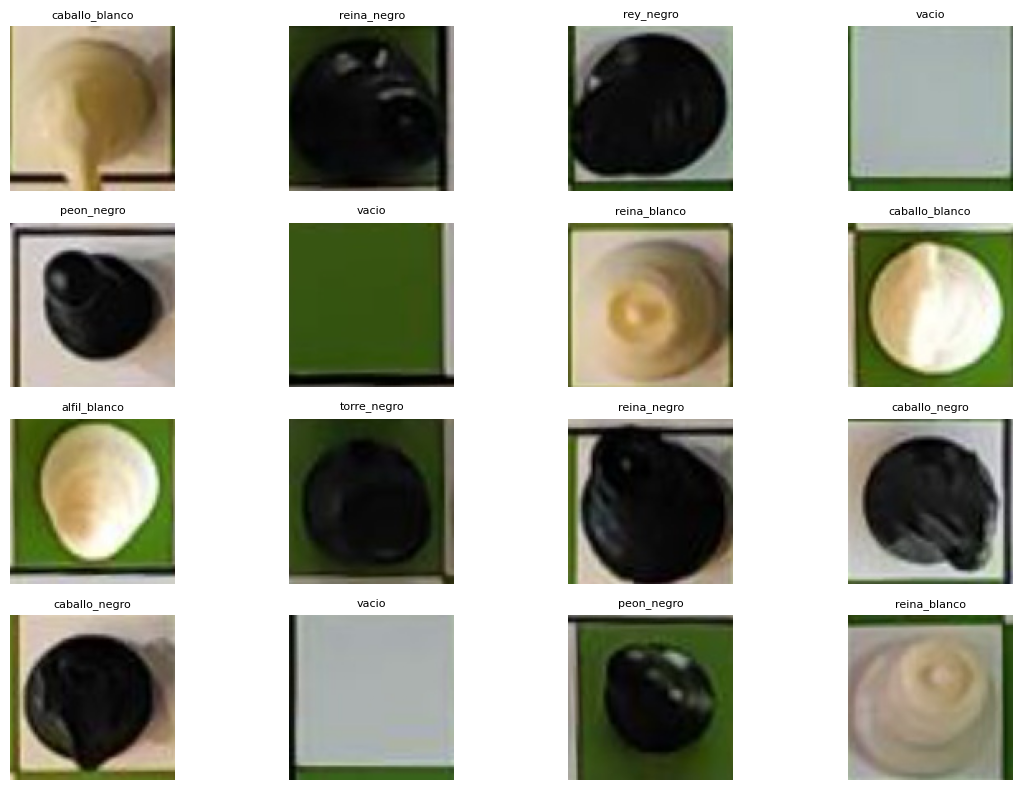

In [4]:
def denormalizar_tensor(img_tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    img = img_tensor.cpu() * std + mean
    return img.clamp(0, 1)

images, labels = next(iter(train_loader))
plt.figure(figsize=(12, 8))
for i in range(min(16, len(images))):
    plt.subplot(4, 4, i + 1)
    img = denormalizar_tensor(images[i]).permute(1, 2, 0).numpy()
    plt.imshow(img)
    plt.title(class_names[int(labels[i])], fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()


## 6. Modelo CNN

In [5]:
class ChessCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        # Con imagenes 100x100 la salida natural tras 4 MaxPool es 6x6.
        # AdaptiveAvgPool mantiene estable la arquitectura si alguna imagen llega con una pequena diferencia de tamano.
        self.pool = nn.AdaptiveAvgPool2d((6, 6))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.35),
            nn.Linear(256 * 6 * 6, 384),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(384, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x)

model = ChessCNN(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", patience=4, factor=0.5)

print(model)


ChessCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)


## 7. Funciones de entrenamiento y evaluacion

In [6]:
def run_epoch(model, loader, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.set_grad_enabled(is_train):
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            if is_train:
                optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            if is_train:
                loss.backward()
                optimizer.step()

            preds = outputs.argmax(dim=1)
            total_loss += loss.item() * images.size(0)
            total_correct += (preds == labels).sum().item()
            total_samples += images.size(0)

    avg_loss = total_loss / total_samples
    avg_acc = total_correct / total_samples
    return avg_loss, avg_acc


def guardar_checkpoint(model, path=MODEL_PATH):
    torch.save({
        "model_state_dict": model.state_dict(),
        "class_names": class_names,
        "img_size": IMG_SIZE,
        "architecture": "ChessCNN_BN_Dropout_100x100_AdaptivePool6x6",
    }, path)


## 8. Entrenar modelo

In [7]:
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
}

best_val_acc = 0.0

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(model, train_loader, optimizer=optimizer)
    val_loss, val_acc = run_epoch(model, val_loader, optimizer=None)
    scheduler.step(val_acc)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        guardar_checkpoint(model, MODEL_PATH)
        best_msg = "<- mejor modelo guardado"
    else:
        best_msg = ""

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
        f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} {best_msg}"
    )

with open(HISTORY_PATH, "w", encoding="utf-8") as f:
    json.dump(history, f, indent=2)

print("Mejor val_acc:", best_val_acc)
print("Modelo guardado en:", MODEL_PATH)
print("Historial guardado en:", HISTORY_PATH)


Epoch 01/35 | train_loss=1.7292 train_acc=0.3949 | val_loss=1.1860 val_acc=0.4964 <- mejor modelo guardado
Epoch 02/35 | train_loss=0.9836 train_acc=0.5847 | val_loss=0.8883 val_acc=0.5829 <- mejor modelo guardado
Epoch 03/35 | train_loss=0.7213 train_acc=0.6892 | val_loss=1.1452 val_acc=0.5144 
Epoch 04/35 | train_loss=0.6443 train_acc=0.7301 | val_loss=0.9279 val_acc=0.5685 
Epoch 05/35 | train_loss=0.5194 train_acc=0.7721 | val_loss=0.8478 val_acc=0.5697 
Epoch 06/35 | train_loss=0.4411 train_acc=0.8086 | val_loss=1.0496 val_acc=0.5252 
Epoch 07/35 | train_loss=0.4806 train_acc=0.7981 | val_loss=0.8476 val_acc=0.5865 <- mejor modelo guardado
Epoch 08/35 | train_loss=0.3531 train_acc=0.8488 | val_loss=0.8002 val_acc=0.6406 <- mejor modelo guardado
Epoch 09/35 | train_loss=0.3451 train_acc=0.8587 | val_loss=1.2444 val_acc=0.6118 
Epoch 10/35 | train_loss=0.3446 train_acc=0.8522 | val_loss=1.0252 val_acc=0.5829 
Epoch 11/35 | train_loss=0.2551 train_acc=0.8946 | val_loss=0.6796 val_acc

## 9. Graficos de precision y perdida

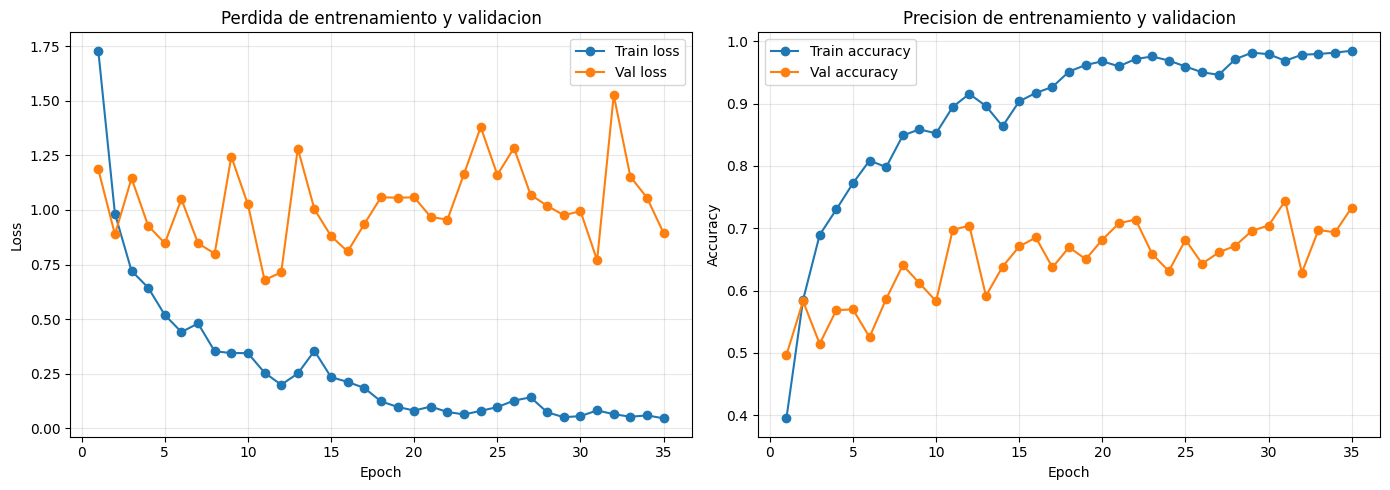

In [8]:
def graficar_historial(history):
    epochs_range = range(1, len(history["train_loss"]) + 1)

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, history["train_loss"], marker="o", label="Train loss")
    plt.plot(epochs_range, history["val_loss"], marker="o", label="Val loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Perdida de entrenamiento y validacion")
    plt.grid(True, alpha=0.3)
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, history["train_acc"], marker="o", label="Train accuracy")
    plt.plot(epochs_range, history["val_acc"], marker="o", label="Val accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("Precision de entrenamiento y validacion")
    plt.grid(True, alpha=0.3)
    plt.legend()

    plt.tight_layout()
    plt.show()


graficar_historial(history)


## 10. Cargar mejor modelo guardado

In [ ]:
def cargar_class_names_desde_json(path=CLASS_NAMES_PATH):
    if Path(path).exists():
        with open(path, "r", encoding="utf-8") as f:
            return json.load(f)
    return None


def cargar_modelo(path=MODEL_PATH):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"No existe el modelo guardado: {path}")

    checkpoint = torch.load(path, map_location=device)

    if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
        loaded_class_names = checkpoint.get("class_names")
        if loaded_class_names is None:
            loaded_class_names = cargar_class_names_desde_json()
        if loaded_class_names is None:
            loaded_class_names = globals().get("class_names")
        if loaded_class_names is None:
            raise ValueError("No se encontraron class_names en el checkpoint ni en class_names.json.")

        loaded_img_size = checkpoint.get("img_size", IMG_SIZE)
        loaded_model = ChessCNN(num_classes=len(loaded_class_names)).to(device)
        try:
            loaded_model.load_state_dict(checkpoint["model_state_dict"])
        except RuntimeError as exc:
            raise RuntimeError(
                "El checkpoint guardado no coincide con la arquitectura actual de 100x100. "
                "Vuelve a entrenar desde la seccion 8 para generar un modelo nuevo, "
                "o restaura la arquitectura anterior si quieres cargar un modelo de 64x64."
            ) from exc
    else:
        loaded_class_names = cargar_class_names_desde_json()
        if loaded_class_names is None:
            loaded_class_names = globals().get("class_names")
        if loaded_class_names is None:
            raise ValueError("El .pth no trae class_names. Define class_names o crea class_names.json.")

        loaded_img_size = IMG_SIZE
        loaded_model = ChessCNN(num_classes=len(loaded_class_names)).to(device)
        try:
            loaded_model.load_state_dict(checkpoint)
        except RuntimeError as exc:
            raise RuntimeError(
                "El .pth no coincide con la arquitectura actual de 100x100. Reentrena el modelo con este cuadernillo."
            ) from exc

    loaded_model.eval()
    return loaded_model, loaded_class_names, int(loaded_img_size)


model, class_names, IMG_SIZE = cargar_modelo(MODEL_PATH)
num_classes = len(class_names)
print("Modelo cargado:", MODEL_PATH)
print("IMG_SIZE:", IMG_SIZE)
print("Clases:", class_names)


## 11. Matriz de confusion

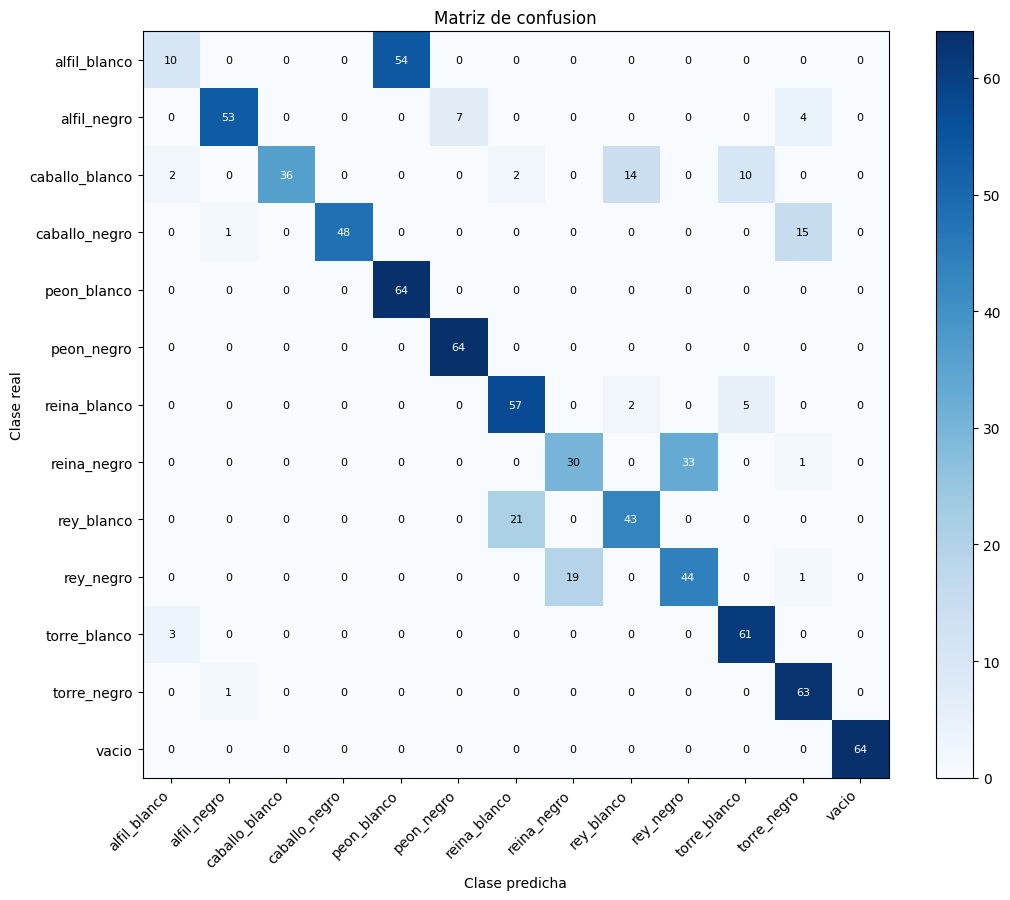

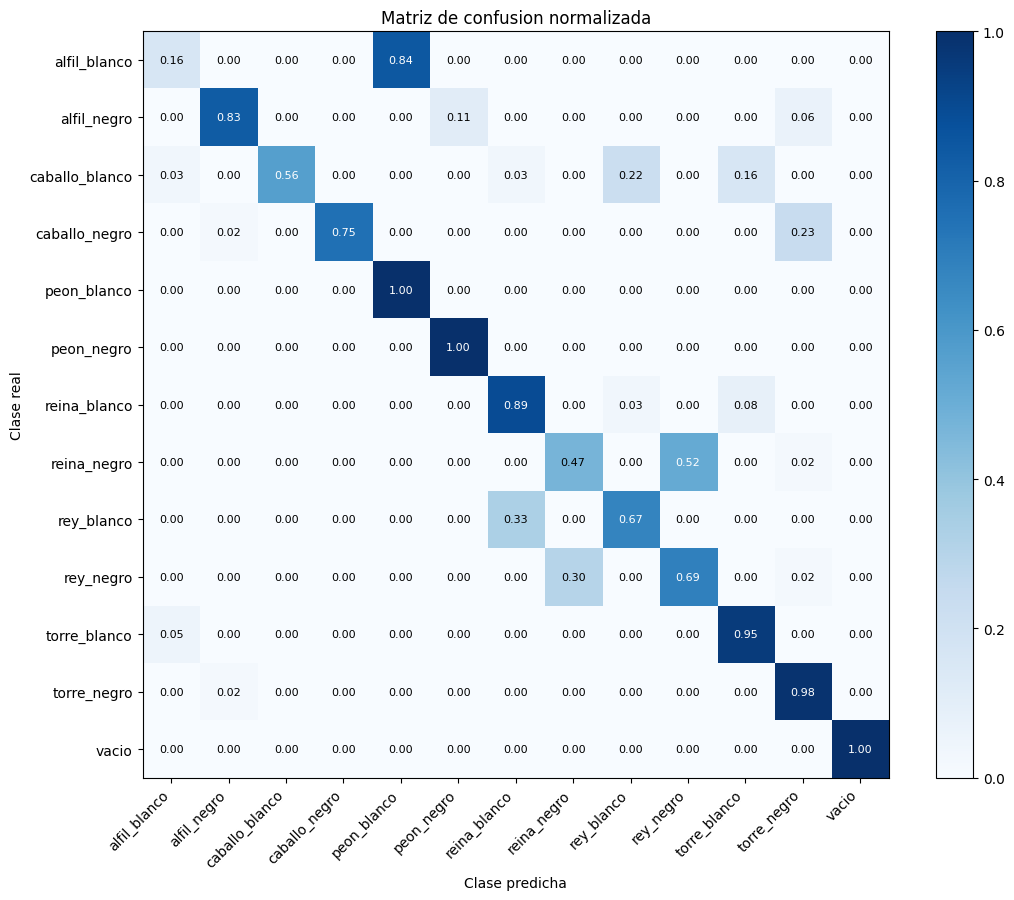

Accuracy validacion: 0.7656


In [23]:
def obtener_predicciones(model, loader):
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            preds = outputs.argmax(dim=1).cpu().numpy()
            y_pred.extend(preds.tolist())
            y_true.extend(labels.numpy().tolist())

    return np.array(y_true), np.array(y_pred)


def matriz_confusion(y_true, y_pred, n_classes):
    cm = np.zeros((n_classes, n_classes), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1
    return cm


def plot_confusion_matrix(cm, class_names, normalize=False):
    if normalize:
        denom = cm.sum(axis=1, keepdims=True)
        cm_plot = np.divide(cm, denom, out=np.zeros_like(cm, dtype=float), where=denom != 0)
    else:
        cm_plot = cm

    plt.figure(figsize=(11, 9))
    plt.imshow(cm_plot, cmap="Blues")
    plt.title("Matriz de confusion" + (" normalizada" if normalize else ""))
    plt.colorbar()
    tick_marks = np.arange(len(class_names))
    plt.xticks(tick_marks, class_names, rotation=45, ha="right")
    plt.yticks(tick_marks, class_names)

    threshold = cm_plot.max() / 2 if cm_plot.max() > 0 else 0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            value = cm_plot[i, j]
            text = f"{value:.2f}" if normalize else str(cm[i, j])
            plt.text(j, i, text, ha="center", va="center", color="white" if value > threshold else "black", fontsize=8)

    plt.ylabel("Clase real")
    plt.xlabel("Clase predicha")
    plt.tight_layout()
    plt.show()


y_true, y_pred = obtener_predicciones(model, val_loader)
cm = matriz_confusion(y_true, y_pred, num_classes)
plot_confusion_matrix(cm, class_names, normalize=False)
plot_confusion_matrix(cm, class_names, normalize=True)

val_accuracy = (y_true == y_pred).mean()
print(f"Accuracy validacion: {val_accuracy:.4f}")


## 12. Prueba con imagenes del dataset o imagenes sueltas

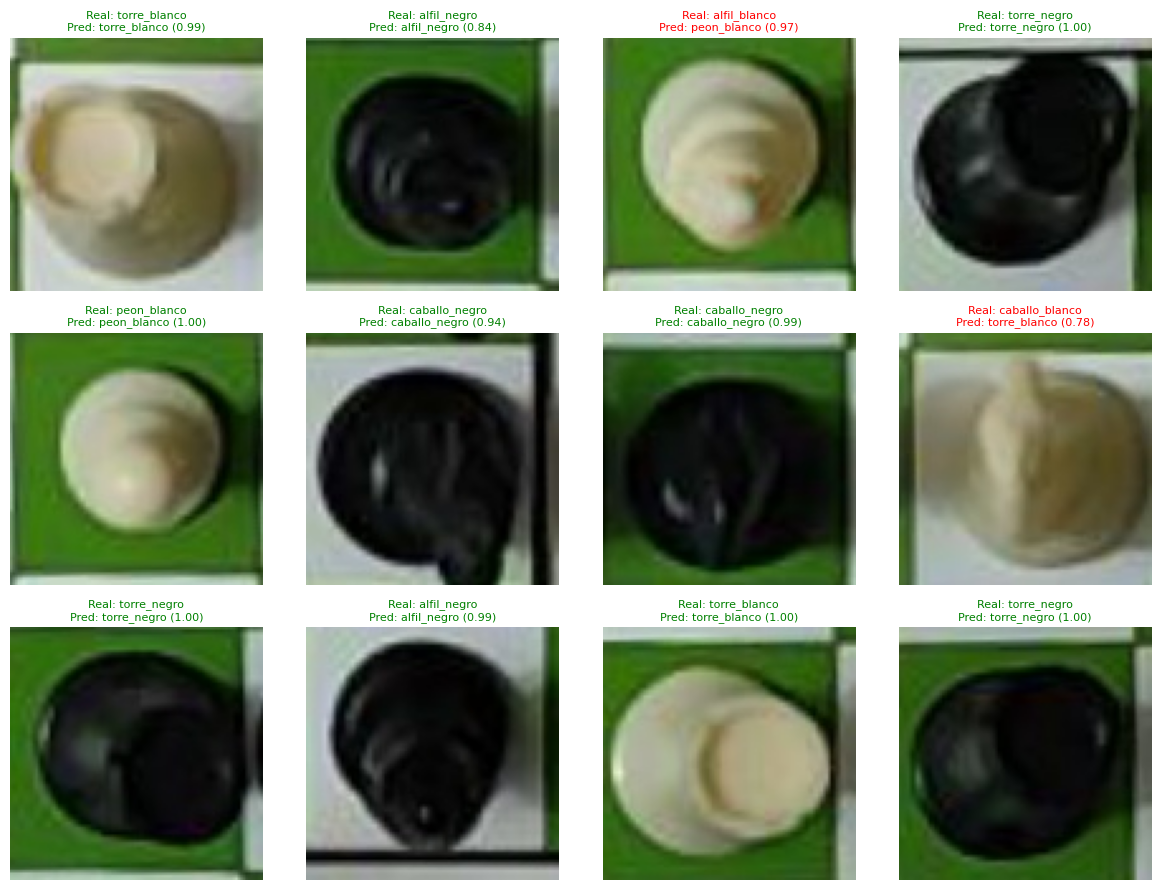

In [24]:
predict_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])


def asegurar_modelo_cargado():
    global model, class_names, num_classes, IMG_SIZE, predict_transform

    if "model" not in globals() or "class_names" not in globals():
        model, class_names, IMG_SIZE = cargar_modelo(MODEL_PATH)
        num_classes = len(class_names)
        predict_transform = transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
        print("Modelo cargado automaticamente:", MODEL_PATH)

    return model, class_names


def predecir_imagen_path(image_path, modelo=None, nombres_clases=None):
    modelo_base, clases_base = asegurar_modelo_cargado()
    modelo = modelo_base if modelo is None else modelo
    nombres_clases = clases_base if nombres_clases is None else nombres_clases

    image_path = Path(image_path)
    img = Image.open(image_path).convert("RGB")
    x = predict_transform(img).unsqueeze(0).to(device)

    modelo.eval()
    with torch.no_grad():
        logits = modelo(x)
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()
        pred_idx = int(np.argmax(probs))

    return {
        "path": image_path,
        "label": nombres_clases[pred_idx],
        "confidence": float(probs[pred_idx]),
        "probs": probs,
    }


def probar_imagenes_aleatorias(dataset_dir=VAL_DIR, n=12):
    asegurar_modelo_cargado()
    all_images = [p for p in Path(dataset_dir).glob("**/*") if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]]
    sample = random.sample(all_images, min(n, len(all_images)))

    cols = 4
    rows = int(np.ceil(len(sample) / cols))
    plt.figure(figsize=(cols * 3, rows * 3))

    for i, path in enumerate(sample):
        result = predecir_imagen_path(path)
        true_label = path.parent.name
        img = Image.open(path).convert("RGB")

        plt.subplot(rows, cols, i + 1)
        plt.imshow(img)
        color = "green" if result["label"] == true_label else "red"
        plt.title(f"Real: {true_label}\nPred: {result['label']} ({result['confidence']:.2f})", color=color, fontsize=8)
        plt.axis("off")

    plt.tight_layout()
    plt.show()


probar_imagenes_aleatorias(VAL_DIR, n=12)


## 13. Probar una imagen especifica

In [ ]:
# Cambia esta ruta por cualquier imagen que quieras probar.
# image_path = ROOT / "Dataset" / "Entrenamiento" / "Val" / "vacio" / "alguna_imagen.jpg"
# result = predecir_imagen_path(image_path)
# print(result["label"], result["confidence"])
# Image.open(result["path"])


# Prueba integrada con DroidCam + ArUco + clasificacion

Esta seccion toma la logica del cuadernillo `PruebaCamara.ipynb`: abre DroidCam, detecta ArUco, endereza tablero, segmenta las 64 casillas, clasifica cada casilla y arma una matriz/tablero con `python-chess`.


## 14. Configuracion de DroidCam

In [6]:
# Ajusta estos datos si DroidCam cambia la IP o el puerto.
DROIDCAM_DEVICE_IP = "10.77.209.23"
DROIDCAM_WIFI_IP = "192.168.1.6"
DROIDCAM_PORT = 4747

CAMERA_SOURCE = f"http://{DROIDCAM_DEVICE_IP}:{DROIDCAM_PORT}/video"
DROIDCAM_URLS = [
    f"http://{DROIDCAM_DEVICE_IP}:{DROIDCAM_PORT}/video",
    f"http://{DROIDCAM_DEVICE_IP}:{DROIDCAM_PORT}/mjpegfeed",
    f"http://{DROIDCAM_WIFI_IP}:{DROIDCAM_PORT}/video",
    f"http://{DROIDCAM_WIFI_IP}:{DROIDCAM_PORT}/mjpegfeed",
]

CAMERA_BACKEND_ACTUAL = None
CAMERA_WIDTH = 1280
CAMERA_HEIGHT = 720
ARUCO_DICT = cv2.aruco.DICT_4X4_50
BOARD_SIZE = 800
CELL_MARGIN = 0.00
CAMERA_OUTPUT_DIR = ROOT / "Dataset" / "prueba_clasificacion_camara"
CAMERA_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("CAMERA_SOURCE:", CAMERA_SOURCE)


CAMERA_SOURCE: http://10.77.209.23:4747/video


## 15. Utilidades de camara para notebook

In [7]:
def mostrar_frame_notebook(frame_bgr, titulo="Frame", figsize=(8, 5)):
    frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=figsize)
    plt.imshow(frame_rgb)
    plt.title(titulo)
    plt.axis("off")
    plt.show()


def abrir_video_capture(source):
    if isinstance(source, int):
        backend = CAMERA_BACKEND_ACTUAL if CAMERA_BACKEND_ACTUAL is not None else cv2.CAP_DSHOW
        cap = cv2.VideoCapture(source, backend)
        cap.set(cv2.CAP_PROP_FRAME_WIDTH, CAMERA_WIDTH)
        cap.set(cv2.CAP_PROP_FRAME_HEIGHT, CAMERA_HEIGHT)
    else:
        cap = cv2.VideoCapture(str(source))
    return cap


def abrir_camara(source=CAMERA_SOURCE):
    cap = abrir_video_capture(source)
    if not cap.isOpened():
        raise RuntimeError(f"No se pudo abrir la fuente de camara: {source}")
    return cap


def leer_primer_frame(source, intentos=25, espera=0.08):
    cap = abrir_video_capture(source)
    try:
        for _ in range(intentos):
            ok, frame = cap.read()
            if ok and frame is not None:
                return True, frame
            time.sleep(espera)
    finally:
        cap.release()
    return False, None


def probar_urls_droidcam(urls=DROIDCAM_URLS):
    ok_urls = []
    for url in urls:
        print("Probando:", url)
        ok, frame = leer_primer_frame(url, intentos=40, espera=0.1)
        if ok:
            ok_urls.append(url)
            print("  OK", frame.shape)
            mostrar_frame_notebook(frame, titulo=url)
        else:
            print("  Sin video")
    return ok_urls


def vista_previa_notebook(source=CAMERA_SOURCE, frames=15, intervalo=0.15):
    cap = abrir_camara(source)
    ultimo = None
    try:
        for i in range(frames):
            ok, frame = cap.read()
            if ok and frame is not None:
                ultimo = frame.copy()
                frame_marcado = frame.copy()
                cv2.putText(frame_marcado, f"Frame {i+1}/{frames}", (25, 45), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 255, 0), 3)
                clear_output(wait=True)
                mostrar_frame_notebook(frame_marcado, titulo=f"Vista previa: {source}")
            time.sleep(intervalo)
    finally:
        cap.release()
    return ultimo

# Si necesitas buscar URL:
# urls_ok = probar_urls_droidcam()
# if urls_ok: CAMERA_SOURCE = urls_ok[0]
# frame_preview = vista_previa_notebook(CAMERA_SOURCE)


## 16. ArUco, enderezado y segmentacion

In [8]:
def ordenar_puntos(pts):
    pts = np.array(pts, dtype="float32")
    suma = pts.sum(axis=1)
    resta = np.diff(pts, axis=1)
    ordenados = np.zeros((4, 2), dtype="float32")
    ordenados[0] = pts[np.argmin(suma)]
    ordenados[2] = pts[np.argmax(suma)]
    ordenados[1] = pts[np.argmin(resta)]
    ordenados[3] = pts[np.argmax(resta)]
    return ordenados


def detectar_aruco(imagen_bgr):
    gray = cv2.cvtColor(imagen_bgr, cv2.COLOR_BGR2GRAY)
    aruco_dict = cv2.aruco.getPredefinedDictionary(ARUCO_DICT)
    params = cv2.aruco.DetectorParameters()
    if hasattr(cv2.aruco, "ArucoDetector"):
        detector = cv2.aruco.ArucoDetector(aruco_dict, params)
        corners, ids, _ = detector.detectMarkers(gray)
    else:
        corners, ids, _ = cv2.aruco.detectMarkers(gray, aruco_dict, parameters=params)
    return corners, ids


def obtener_esquinas_tablero_desde_aruco(corners, ids):
    if ids is None or len(ids) < 4:
        total = 0 if ids is None else len(ids)
        raise ValueError(f"Se necesitan 4 ArUco visibles. Detectados: {total}")

    datos = []
    for marker_corners, marker_id in zip(corners, ids.flatten()):
        pts = marker_corners.reshape(4, 2)
        datos.append({"id": int(marker_id), "corners": pts, "centro": pts.mean(axis=0)})

    datos = sorted(datos, key=lambda d: d["centro"][1])[:4]
    arriba = sorted(datos[:2], key=lambda d: d["centro"][0])
    abajo = sorted(datos[2:], key=lambda d: d["centro"][0])

    marker_tl = arriba[0]
    marker_tr = arriba[1]
    marker_bl = abajo[0]
    marker_br = abajo[1]

    board_tl = marker_tl["corners"][2]
    board_tr = marker_tr["corners"][3]
    board_br = marker_br["corners"][0]
    board_bl = marker_bl["corners"][1]

    return ordenar_puntos(np.array([board_tl, board_tr, board_br, board_bl], dtype="float32"))


def enderezar_tablero(imagen_bgr, corners, size=BOARD_SIZE):
    corners = ordenar_puntos(corners)
    destino = np.array([[0, 0], [size - 1, 0], [size - 1, size - 1], [0, size - 1]], dtype="float32")
    matriz = cv2.getPerspectiveTransform(corners, destino)
    return cv2.warpPerspective(imagen_bgr, matriz, (size, size))


def detectar_y_enderezar_tablero(imagen_bgr):
    corners, ids = detectar_aruco(imagen_bgr)
    corners_tablero = obtener_esquinas_tablero_desde_aruco(corners, ids)
    tablero_recto = enderezar_tablero(imagen_bgr, corners_tablero)
    debug = imagen_bgr.copy()
    cv2.aruco.drawDetectedMarkers(debug, corners, ids)
    cv2.polylines(debug, [corners_tablero.astype(int)], True, (0, 255, 0), 4)
    return tablero_recto, debug, corners_tablero, ids


def nombre_casilla_ajedrez(fila, col):
    columnas = ["a", "b", "c", "d", "e", "f", "g", "h"]
    filas = ["8", "7", "6", "5", "4", "3", "2", "1"]
    return columnas[col] + filas[fila]


def segmentar_casillas(tablero_bgr, n=8, margin=CELL_MARGIN):
    h, w = tablero_bgr.shape[:2]
    cell_h = h // n
    cell_w = w // n
    mx = int(cell_w * margin)
    my = int(cell_h * margin)
    casillas = []
    for fila in range(n):
        for col in range(n):
            y1, y2 = fila * cell_h, (fila + 1) * cell_h
            x1, x2 = col * cell_w, (col + 1) * cell_w
            crop = tablero_bgr[y1 + my:y2 - my, x1 + mx:x2 - mx]
            casillas.append({"casilla": nombre_casilla_ajedrez(fila, col), "fila": fila, "columna": col, "imagen": crop})
    return casillas


## 17. Clasificar tablero y crear matriz con python-chess

In [9]:
LABEL_TO_PIECE = {
    "vacio": None,
    "peon_blanco": "P", "caballo_blanco": "N", "alfil_blanco": "B", "torre_blanco": "R", "reina_blanco": "Q", "rey_blanco": "K",
    "peon_negro": "p", "caballo_negro": "n", "alfil_negro": "b", "torre_negro": "r", "reina_negro": "q", "rey_negro": "k",
}


def recargar_modelo_clasificacion(path=MODEL_PATH):
    """
    Recarga SIEMPRE el modelo desde outputs y reconstruye el transform con el img_size guardado.
    Esto evita errores si el kernel quedo con IMG_SIZE viejo, por ejemplo un valor viejo distinto de 100.
    """
    global model, class_names, num_classes, IMG_SIZE, predict_transform

    if "ChessCNN" not in globals():
        raise RuntimeError("Primero ejecuta la celda donde se define la clase ChessCNN.")

    checkpoint = torch.load(path, map_location=device)
    if not isinstance(checkpoint, dict) or "model_state_dict" not in checkpoint:
        raise ValueError("El modelo guardado debe ser un checkpoint con 'model_state_dict'.")

    class_names = checkpoint.get("class_names")
    if class_names is None and Path(CLASS_NAMES_PATH).exists():
        with open(CLASS_NAMES_PATH, "r", encoding="utf-8") as f:
            class_names = json.load(f)
    if class_names is None:
        raise ValueError("No se encontraron class_names en el checkpoint ni en class_names.json.")

    IMG_SIZE = int(checkpoint.get("img_size", 100))
    num_classes = len(class_names)

    model = ChessCNN(num_classes=num_classes).to(device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    predict_transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])

    print("Modelo recargado desde:", path)
    print("IMG_SIZE usado para clasificar:", IMG_SIZE)
    print("Clases:", class_names)
    return model, class_names


def predecir_casilla_bgr(img_bgr, modelo=None, nombres_clases=None):
    if "model" not in globals() or "predict_transform" not in globals():
        recargar_modelo_clasificacion(MODEL_PATH)

    modelo = model if modelo is None else modelo
    nombres_clases = class_names if nombres_clases is None else nombres_clases

    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    pil_img = Image.fromarray(img_rgb)
    x = predict_transform(pil_img).unsqueeze(0).to(device)

    modelo.eval()
    with torch.no_grad():
        logits = modelo(x)
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()
        pred_idx = int(np.argmax(probs))
    return nombres_clases[pred_idx], float(probs[pred_idx])


def clasificar_casillas(casillas):
    predicciones = {}
    for item in casillas:
        label, confidence = predecir_casilla_bgr(item["imagen"])
        predicciones[item["casilla"]] = {
            "label": label,
            "confidence": confidence,
            "fila": item["fila"],
            "columna": item["columna"],
        }
    return predicciones


def predicciones_a_matriz_y_board(predicciones, turn=None):
    matriz = []
    board = chess.Board(None) if chess is not None else None

    for fila in range(8):
        fila_vals = []
        for col in range(8):
            sq = nombre_casilla_ajedrez(fila, col)
            label = predicciones[sq]["label"]
            symbol = LABEL_TO_PIECE.get(label)
            fila_vals.append(symbol if symbol is not None else ".")
            if board is not None and symbol is not None:
                board.set_piece_at(chess.parse_square(sq), chess.Piece.from_symbol(symbol))
        matriz.append(fila_vals)

    if board is not None:
        board.turn = chess.WHITE if turn is None else turn
        board.castling_rights = 0
        board.ep_square = None
    return matriz, board


def mostrar_matriz(matriz):
    print("   a b c d e f g h")
    for i, fila in enumerate(matriz):
        print(8 - i, " ", " ".join(fila))


def mostrar_board_chess(board):
    if chess is None or board is None:
        print("python-chess no esta disponible.")
        return
    display(SVG(chess.svg.board(board=board, size=420)))
    print("FEN:", board.fen())

# Recarga limpia para esta seccion, aunque el kernel tenga variables antiguas.
model, class_names = recargar_modelo_clasificacion(MODEL_PATH)


Modelo recargado desde: c:\Users\User\Desktop\Brazo Robotico\Modelo de Clasificacion\outputs\modelo_ajedrez_entrenamiento.pth
IMG_SIZE usado para clasificar: 64
Clases: ['alfil_blanco', 'alfil_negro', 'caballo_blanco', 'caballo_negro', 'peon_blanco', 'peon_negro', 'reina_blanco', 'reina_negro', 'rey_blanco', 'rey_negro', 'torre_blanco', 'torre_negro', 'vacio']


## 18. Capturar, segmentar, clasificar y guardar resultados

Probando: http://10.77.209.23:4747/video
  Sin video
Probando: http://10.77.209.23:4747/mjpegfeed
  Sin video
Probando: http://192.168.1.6:4747/video
  OK (720, 1280, 3)


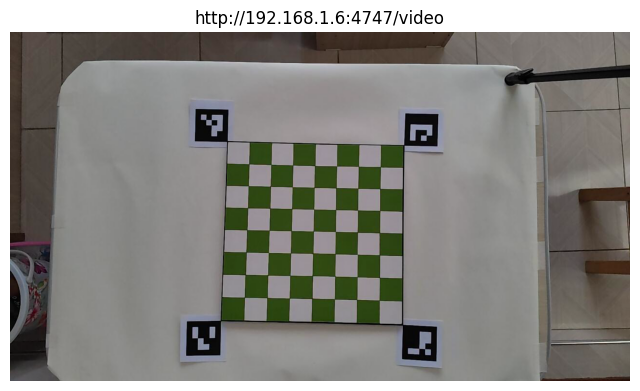

Probando: http://192.168.1.6:4747/mjpegfeed
  Sin video
Modelo recargado desde: c:\Users\User\Desktop\Brazo Robotico\Modelo de Clasificacion\outputs\modelo_ajedrez_entrenamiento.pth
IMG_SIZE usado para clasificar: 64
Clases: ['alfil_blanco', 'alfil_negro', 'caballo_blanco', 'caballo_negro', 'peon_blanco', 'peon_negro', 'reina_blanco', 'reina_negro', 'rey_blanco', 'rey_negro', 'torre_blanco', 'torre_negro', 'vacio']
Buscando tablero con 4 ArUco en fuente: http://192.168.1.6:4747/video
Tablero detectado en frame 1. ArUco detectados: 4


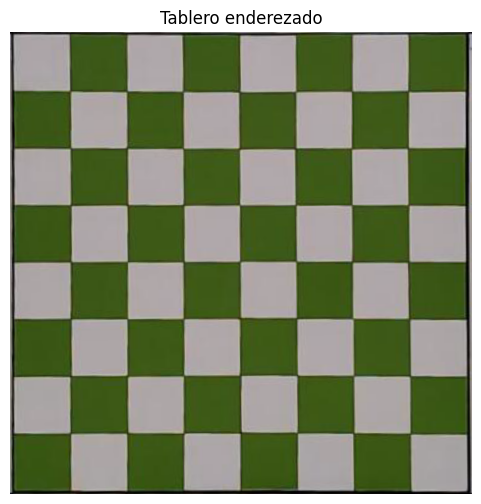

   a b c d e f g h
8   . . . . . . . .
7   . . . . . . . .
6   . . . . . . . .
5   . . . . . . . .
4   . . . . . . . .
3   . . . . . . . .
2   . . . . . . . .
1   . . . . . . . .


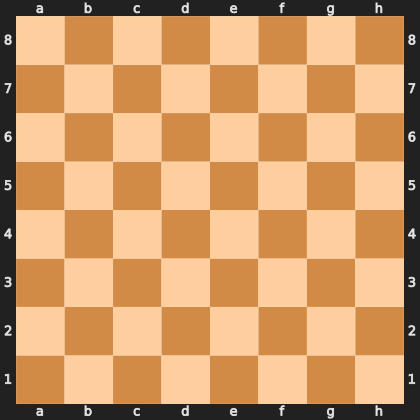

FEN: 8/8/8/8/8/8/8/8 w - - 0 1
Predicciones guardadas: c:\Users\User\Desktop\Brazo Robotico\Dataset\prueba_clasificacion_camara\predicciones_20260523_163455.json
Matriz guardada: c:\Users\User\Desktop\Brazo Robotico\Dataset\prueba_clasificacion_camara\matriz_20260523_163455.json


In [12]:
def capturar_tablero(source=CAMERA_SOURCE, max_frames=120, mostrar_cada=10):
    cap = abrir_camara(source)
    tablero_capturado = None
    frame_capturado = None
    debug_capturado = None
    ultimo_frame = None
    ultimo_error = "Aun no se procesa ningun frame."

    print(f"Buscando tablero con 4 ArUco en fuente: {source}")
    try:
        for frame_idx in range(1, max_frames + 1):
            ok, frame = cap.read()
            if not ok or frame is None:
                ultimo_error = "No se pudo leer frame de la camara."
                time.sleep(0.05)
                continue

            ultimo_frame = frame.copy()
            try:
                tablero_actual, debug_actual, corners_tablero, ids = detectar_y_enderezar_tablero(frame)
                tablero_capturado = tablero_actual.copy()
                frame_capturado = frame.copy()
                debug_capturado = debug_actual.copy()
                print(f"Tablero detectado en frame {frame_idx}. ArUco detectados: {len(ids)}")
                break
            except Exception as exc:
                ultimo_error = str(exc)

            if mostrar_cada and frame_idx % mostrar_cada == 0:
                frame_marcado = frame.copy()
                cv2.putText(frame_marcado, ultimo_error[:80], (25, 45), cv2.FONT_HERSHEY_SIMPLEX, 0.75, (0, 0, 255), 2)
                clear_output(wait=True)
                print(f"Frame {frame_idx}/{max_frames}. {ultimo_error}")
                mostrar_frame_notebook(frame_marcado, titulo="Buscando ArUco")
            time.sleep(0.03)
    finally:
        cap.release()

    if tablero_capturado is None:
        print("No se detecto el tablero.")
        if ultimo_frame is not None:
            mostrar_frame_notebook(ultimo_frame, titulo="Ultimo frame capturado")
        return None, None, None

    timestamp = time.strftime("%Y%m%d_%H%M%S")
    cv2.imwrite(str(CAMERA_OUTPUT_DIR / f"captura_original_{timestamp}.jpg"), frame_capturado)
    cv2.imwrite(str(CAMERA_OUTPUT_DIR / f"captura_debug_aruco_{timestamp}.jpg"), debug_capturado)
    cv2.imwrite(str(CAMERA_OUTPUT_DIR / f"tablero_enderezado_{timestamp}.jpg"), tablero_capturado)
    return frame_capturado, tablero_capturado, timestamp


def prueba_clasificacion_con_camara(source=CAMERA_SOURCE):
    recargar_modelo_clasificacion(MODEL_PATH)
    frame, tablero_recto, timestamp = capturar_tablero(source)
    if tablero_recto is None:
        return None

    mostrar_frame_notebook(tablero_recto, titulo="Tablero enderezado", figsize=(6, 6))
    casillas = segmentar_casillas(tablero_recto)
    predicciones = clasificar_casillas(casillas)
    matriz, board = predicciones_a_matriz_y_board(predicciones)

    mostrar_matriz(matriz)
    mostrar_board_chess(board)

    out_json = CAMERA_OUTPUT_DIR / f"predicciones_{timestamp}.json"
    out_matrix = CAMERA_OUTPUT_DIR / f"matriz_{timestamp}.json"
    with open(out_json, "w", encoding="utf-8") as f:
        json.dump(predicciones, f, ensure_ascii=False, indent=2)
    with open(out_matrix, "w", encoding="utf-8") as f:
        json.dump({"matriz": matriz, "fen": board.fen() if board is not None else None}, f, ensure_ascii=False, indent=2)

    print("Predicciones guardadas:", out_json)
    print("Matriz guardada:", out_matrix)
    return {"frame": frame, "tablero_recto": tablero_recto, "casillas": casillas, "predicciones": predicciones, "matriz": matriz, "board": board}

# Primero verifica la fuente:
urls_ok = probar_urls_droidcam()
if urls_ok: CAMERA_SOURCE = urls_ok[0]
resultado_camara = prueba_clasificacion_con_camara(CAMERA_SOURCE)
